# 01 · Exploration and preprocessing

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Wrote and ran all code in this notebook and in the shared module `bikeshare_common.py` (also used by 02–05).
- Chose every cleaning rule, threshold, derived column and chart in this notebook.

**Not done by Claude**
- No interpretation of any result and no written findings. Every `_Team notes:_` cell is left empty for the team.
- Cluster names or labels in words: none are given in the notebook.
- The team's own files (`data-cleanup.ipynb`, `Scratchpad.ipynb`, `FINDINGS.md`) were not edited.
- Bike-type cleaning was not redone: it reads `data/cleaned/bike_types_clean.csv` from the team's `data-cleanup.ipynb`.
- No trip rows and no status rows are dropped here. Problems are flagged with columns, not removed.

_Team notes:_

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import bikeshare_common as bc

bc.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
raw = bc.load_raw()
trips, cities, bike_types, bikes, stations, status = (raw[k] for k in
    ["trips", "cities", "bike_types", "bikes", "stations", "status"])
{k: v.shape for k, v in raw.items()}

{'trips': (1161376, 13),
 'cities': (267, 7),
 'bike_types': (121, 11),
 'bikes': (88436, 3),
 'stations': (2932, 11),
 'status': (2925967, 8)}

## 1. Referential integrity between tables

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Share of matching foreign keys for each table pair; start-station city vs trip city; timezone per country.

**Not done by Claude**
- Trips whose station ids are missing from `stations.csv` are kept as they are, not repaired or dropped.

In [2]:
st_ids = set(stations.id)
checks = {
    "trips.bike_id in bikes": trips.bike_id.isin(bikes.id).mean(),
    "trips.city_id in cities": trips.city_id.isin(cities.id).mean(),
    "trips.station_id_start in stations (non-null)": trips.station_id_start.dropna().isin(st_ids).mean(),
    "trips.station_id_end in stations (non-null)": trips.station_id_end.dropna().isin(st_ids).mean(),
    "bikes.bike_type_id in bike_types": bikes.bike_type_id.isin(bike_types.id).mean(),
    "stations.city_id in cities": stations.city_id.isin(cities.id).mean(),
    "status.station_id in stations": status.station_id.isin(st_ids).mean(),
}
pd.Series(checks, name="share matched").round(4).to_frame()

,share matched
trips.bike_id in bikes,1.0000
trips.city_id in cities,1.0000
trips.station_id_start in stations (non-null),0.9844
trips.station_id_end in stations (non-null),0.9268
bikes.bike_type_id in bike_types,1.0000
stations.city_id in cities,1.0000
status.station_id in stations,1.0000


In [3]:
# start station of a trip should be in the same city as the trip
st_city = stations.set_index("id").city_id
m = trips.station_id_start.notna() & trips.station_id_start.isin(st_ids)
print("start station city == trip city:", (trips.loc[m, "station_id_start"].map(st_city) == trips.loc[m, "city_id"]).mean())
unknown_st = trips.loc[trips.station_id_start.notna() & ~trips.station_id_start.isin(st_ids), "station_id_start"]
print("trips with start station missing from stations.csv:", len(unknown_st), "distinct ids:", unknown_st.nunique())

start station city == trip city: 0.9944697046498253
trips with start station missing from stations.csv: 16702 distinct ids: 838


In [4]:
# timezone column vs country
cities.groupby("country").timezone.unique().to_frame()

,timezone
country,
AT,[Europe/Berlin]
CH,[Europe/Brussels]
CY,[Asia/Istanbul]
CZ,[Europe/Berlin]
DE,"[Europe/Berlin, Europe/Rome]"
ES,"[Atlantic/Canary, Europe/Berlin, Europe/Brussels]"
GB,[Europe/London]
HR,[Europe/Berlin]
IT,[Europe/Berlin]


_Team notes:_

## 2. Trips: enrichment and cleaning

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Joined bikes, bike types and cities onto trips; e-bike and cargo flags from `propulsion_filled` / `form_factor`.
- Battery values set to NaN on human bikes (rule taken from `FINDINGS.md`); `battery_used` = start − end.
- Local time from `cities.timezone`; straight-line speed; check of `distance` against haversine; table of min/max bounds.
- Flags for free-floating start/end and for round trips (distance < 100 m, since no trip has start station = end station).
- Free-floating ends in cities with `return_to_official_only`; distance from free-floating ends to the nearest station (BallTree).

**Not done by Claude**
- No outlier removal. The file is already bounded upstream (speed never exceeds about 15 km/h), so an early 35 km/h rule was dropped.
- Negative `battery_used` values are reported, not corrected.
- The nearest-station search uses all stations, not only those in the trip's own city.
- Real route length is unknown; only straight-line distance is used.

In [5]:
bt = bike_types.rename(columns={"id": "bike_type_id", "name": "bike_type_name"})[
    ["bike_type_id", "bike_type_name", "form_factor", "propulsion_filled", "rider_capacity", "battery_capacity", "type_info_missing"]]
t = trips.merge(bikes.rename(columns={"id": "bike_id"}), on="bike_id", how="left", validate="many_to_one")
t = t.merge(bt, on="bike_type_id", how="left", validate="many_to_one")
t = t.merge(cities.rename(columns={"id": "city_id", "name": "city_name", "lat": "city_lat", "lon": "city_lon"})[
    ["city_id", "city_name", "city_lat", "city_lon", "timezone", "country", "return_to_official_only"]], on="city_id", how="left")
t["ebike"] = (t.propulsion_filled == "electric_assist").astype("int8")
t["cargo"] = (t.form_factor == "cargo").astype("int8")
t.propulsion_filled.value_counts(dropna=False)

propulsion_filled
human              981285
electric_assist    180091
Name: count, dtype: int64

In [6]:
# battery readings on human bikes -> NaN (see FINDINGS.md)
human_batt = (t.ebike == 0) & (t.battery_start.notna() | t.battery_end.notna())
print("human-bike trips with battery values:", human_batt.sum())
t.loc[t.ebike == 0, ["battery_start", "battery_end"]] = np.nan
t["battery_used"] = t.battery_start - t.battery_end
print("e-bike trips with battery data:", t.loc[t.ebike == 1, "battery_used"].notna().mean().round(3))
t.loc[t.ebike == 1, "battery_used"].describe(percentiles=[.01, .05, .5, .95, .99])

human-bike trips with battery values: 302
e-bike trips with battery data: 0.934


count    168216.000000
mean          4.298242
std           6.671002
min        -100.000000
1%           -2.000000
5%            0.000000
50%           3.000000
95%          14.000000
99%          27.000000
max         100.000000
Name: battery_used, dtype: float64

In [7]:
# negative battery use = charged during trip / swapped battery
eb = t[(t.ebike == 1) & t.battery_used.notna()]
print("share with battery_used < 0:", (eb.battery_used < 0).mean().round(3))
print("share with battery_used == 0:", (eb.battery_used == 0).mean().round(3))

share with battery_used < 0: 0.019
share with battery_used == 0: 0.265


In [8]:
# local time
t["start_local"] = bc.local_time(t.time_start, t.timezone)
t = bc.add_calendar(t, "start_local")
t["date"] = t.start_local.dt.normalize()
t["start_utc"] = pd.to_datetime(t.time_start, unit="s")
t[["start_utc", "start_local", "timezone", "hour", "dow"]].head()

,start_utc,start_local,timezone,hour,dow
0,2022-11-25 11:48:01,2022-11-25 12:48:01,Europe/Berlin,12,4
1,2022-12-01 12:21:01,2022-12-01 13:21:01,Europe/Berlin,13,3
2,2022-12-05 14:52:01,2022-12-05 15:52:01,Europe/Berlin,15,0
3,2022-12-06 17:43:01,2022-12-06 18:43:01,Europe/Berlin,18,1
4,2022-12-20 05:28:01,2022-12-20 06:28:01,Europe/Berlin,6,1


In [9]:
# duration resolution
print("duration multiple of 60 s:", (t.duration % 60 == 0).mean())
print("min / max duration (min):", t.duration.min() / 60, t.duration.max() / 60)
print("min / max distance (m):", t.distance.min(), t.distance.max())

duration multiple of 60 s: 0.9690436172264624
min / max duration (min): 2.0166666666666666 479.0
min / max distance (m): 50.0136495 19999.4575919


In [10]:
t["speed_kmh"] = t.distance / t.duration * 3.6
t["dist_check_m"] = bc.haversine_m(t.lat_start, t.lon_start, t.lat_end, t.lon_end)
print("relative diff between given distance and haversine (median):",
      ((t.dist_check_m - t.distance).abs() / t.distance).median().round(4))
t.groupby("ebike").speed_kmh.describe(percentiles=[.5, .9, .99, .999]).round(2)

relative diff between given distance and haversine (median): 0.0


,count,mean,std,min,50%,90%,99%,99.9%,max
ebike,,,,,,,,,
0,981285.0,7.16,3.19,0.25,7.39,11.16,13.92,14.88,15.05
1,180091.0,8.20,3.75,0.25,8.53,13.03,14.80,15.04,15.05


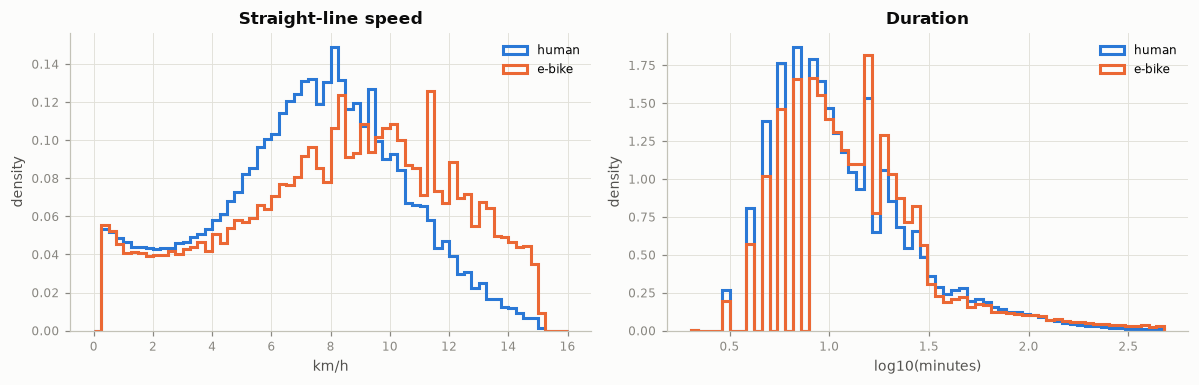

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.linspace(0, 16, 65)
for e, lab in [(0, "human"), (1, "e-bike")]:
    ax[0].hist(t.loc[t.ebike == e, "speed_kmh"], bins=bins, density=True, histtype="step", lw=2, label=lab)
ax[0].set(title="Straight-line speed", xlabel="km/h", ylabel="density")
ax[0].legend()
for e, lab in [(0, "human"), (1, "e-bike")]:
    ax[1].hist(np.log10(t.loc[t.ebike == e, "duration"] / 60), bins=60, density=True, histtype="step", lw=2, label=lab)
ax[1].set(title="Duration", xlabel="log10(minutes)", ylabel="density")
ax[1].legend()
plt.tight_layout()
plt.show()

In [12]:
# hard bounds of the provided sample (upstream filter)
bounds = pd.DataFrame({
    "min": [t.duration.min() / 60, t.distance.min(), t.speed_kmh.min()],
    "max": [t.duration.max() / 60, t.distance.max(), t.speed_kmh.max()]},
    index=["duration (min)", "distance (m)", "straight-line speed (km/h)"])
print("trips within 1% of the speed ceiling:", (t.speed_kmh > 0.99 * t.speed_kmh.max()).mean().round(4))
bounds.round(2)

trips within 1% of the speed ceiling: 0.0016


,min,max
duration (min),2.02,479.00
distance (m),50.01,19999.46
straight-line speed (km/h),0.25,15.05


In [13]:
# station-based vs free-floating, round trips
t["start_free"] = t.station_id_start.isna().astype("int8")
t["end_free"] = t.station_id_end.isna().astype("int8")
t["same_station"] = (t.station_id_start == t.station_id_end).astype("int8")
t["round_trip"] = ((t.same_station == 1) | (t.distance < 100)).astype("int8")
t["dist_centre_start_km"] = bc.haversine_m(t.lat_start, t.lon_start, t.city_lat, t.city_lon) / 1000
t["dist_centre_end_km"] = bc.haversine_m(t.lat_end, t.lon_end, t.city_lat, t.city_lon) / 1000
print("trips with start station == end station:", t.same_station.sum())
t[["start_free", "end_free", "same_station", "round_trip"]].mean().round(4).to_frame("share")

trips with start station == end station: 0


,share
start_free,0.0768
end_free,0.1050
same_station,0.0000
round_trip,0.0018


In [14]:
# round trips: distance is near zero but duration is not -> straight-line distance hides the real ride
t.groupby("round_trip")[["duration", "distance", "speed_kmh"]].median().assign(duration_min=lambda d: d.duration / 60)

,duration,distance,speed_kmh,duration_min
round_trip,,,,
0,720.0,1348.261526,7.544095,12.0
1,300.0,74.337894,0.809471,5.0


In [15]:
# data-quality: free-floating trips in cities that require return to an official station
q = t.groupby("return_to_official_only")[["start_free", "end_free"]].mean()
q

,start_free,end_free
return_to_official_only,,
False,0.106339,0.152806
True,0.070646,0.094963


In [16]:
viol = (t[t.return_to_official_only]
        .groupby("city_name").agg(trips=("end_free", "size"), end_free_share=("end_free", "mean"))
        .query("trips > 2000").sort_values("end_free_share", ascending=False))
viol.head(10).round(3)

,trips,end_free_share
city_name,,
Oldenburg,22909,0.729
Walldorf,28458,0.673
Rīga,5797,0.355
Nottwil,5587,0.256
Mobic,27073,0.236
Eifel e-Bike,4918,0.222
Hanau,2253,0.210
Worms,10749,0.190
Bergisches e-Bike,7400,0.182


In [17]:
# where do free-floating trips end relative to the nearest station of the city?
from sklearn.neighbors import BallTree
st_rad = np.radians(stations[["lat", "lon"]].values)
tree = BallTree(st_rad, metric="haversine")
ff = t[t.end_free == 1]
d, _ = tree.query(np.radians(ff[["lat_end", "lon_end"]].values), k=1)
ff_dist = pd.Series(d[:, 0] * 6_371_000, index=ff.index)
print("free-floating trip end: distance to nearest station (m)")
ff_dist.describe(percentiles=[.25, .5, .75, .9]).round(0)

free-floating trip end: distance to nearest station (m)


count    121904.0
mean        987.0
std        3190.0
min           0.0
25%         102.0
50%         233.0
75%         672.0
90%        1858.0
max       78061.0
dtype: float64

_Team notes:_

## 3. Concentration across cities

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Trips per city, share of the top 10 / top 50 cities, Gini coefficient, per-country table.

**Not done by Claude**
- No normalisation by population or fleet size.

In [18]:
city_trips = t.groupby(["city_id", "city_name", "country"]).size().sort_values(ascending=False).rename("trips").reset_index()
share = city_trips.trips.cumsum() / city_trips.trips.sum()
print("cities with trips:", len(city_trips), "| cities with none:", (~cities.id.isin(city_trips.city_id)).sum())
print("top 10 cities share of trips:", share.iloc[9].round(3), "| top 50:", share.iloc[49].round(3))
lor = np.r_[0, np.sort(city_trips.trips.values).cumsum() / city_trips.trips.sum()]
gini = 1 - 2 * np.trapezoid(lor, dx=1 / (len(lor) - 1))
print("Gini of trips across cities:", round(gini, 3))
city_trips.head(15)

cities with trips: 185 | cities with none: 82
top 10 cities share of trips: 0.23 | top 50: 0.741
Gini of trips across cities: 0.617


,city_id,city_name,country,trips
0,848,Esplugues de Llobregat,ES,29661
1,592,Walldorf,DE,28458
2,88,Sursee Plus,CH,28230
3,530,Mönchengladbach,DE,27232
4,817,Mobic,DE,27073
5,856,Sant Boi de Llobregat,ES,26840
6,749,Getxo,ES,25874
7,496,Koszalin,PL,25160
8,251,Lublin,PL,24785
9,853,Sant Just Desvern,ES,24031


In [19]:
by_country = t.groupby("country").agg(trips=("bike_id", "size"), cities=("city_id", "nunique"),
                                      ebike_share=("ebike", "mean"), median_min=("duration", lambda x: x.median() / 60),
                                      median_km=("distance", lambda x: x.median() / 1000))
by_country.sort_values("trips", ascending=False).round(3)

,trips,cities,ebike_share,median_min,median_km
country,,,,,
DE,357137,59,0.083,10.0,1.217
PL,297269,43,0.012,14.0,1.409
ES,116439,9,0.759,12.0,1.423
CZ,86743,9,0.000,8.0,0.995
GB,70961,4,0.041,18.0,2.337
CH,68975,12,0.000,9.0,1.094
AT,64143,19,0.001,12.0,1.309
HR,52960,18,0.444,16.0,1.849
SI,34444,9,0.912,13.0,1.646


_Team notes:_

## 4. Temporal patterns (local time)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Share of trips by local hour (weekday/weekend), day × hour heatmap, median duration by hour, monthly totals and trips per active bike.

**Not done by Claude**
- No public-holiday calendar.
- Monthly changes are not separated from changes in which cities are active.

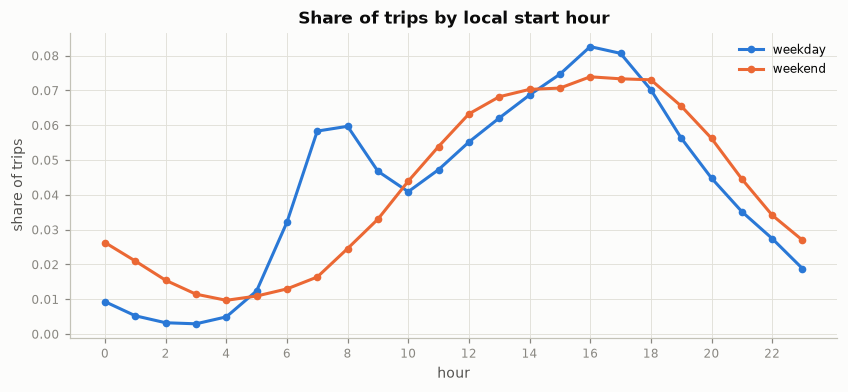

In [20]:
hourly = t.groupby(["weekend", "hour"]).size().unstack(0)
hourly = hourly / hourly.sum()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(hourly.index, hourly[0], label="weekday", marker="o", ms=4)
ax.plot(hourly.index, hourly[1], label="weekend", marker="o", ms=4)
ax.set(title="Share of trips by local start hour", xlabel="hour", ylabel="share of trips", xticks=range(0, 24, 2))
ax.legend()
plt.show()

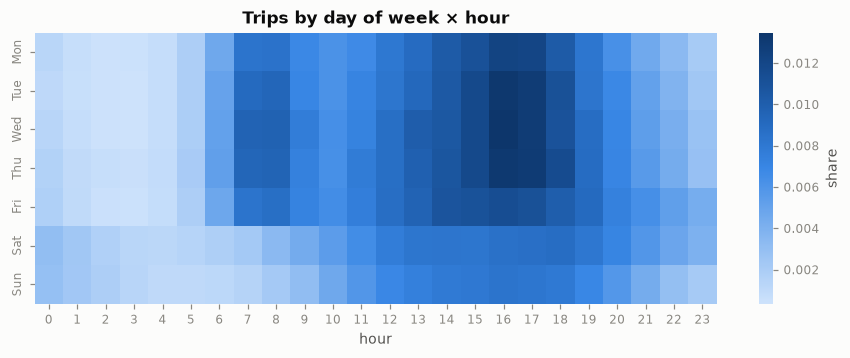

In [21]:
dh = t.groupby(["dow", "hour"]).size().unstack()
fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(dh / dh.values.sum(), cmap=bc.SEQ, ax=ax, cbar_kws={"label": "share"})
ax.set(title="Trips by day of week × hour", yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], xlabel="hour", ylabel="")
plt.show()

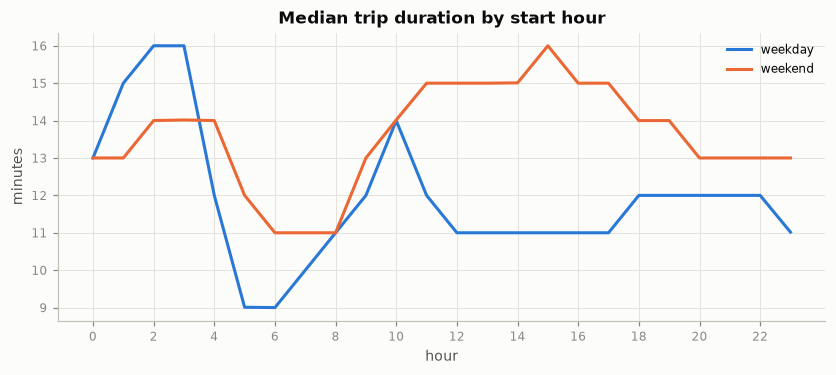

In [22]:
# duration by hour: commute hours are short, afternoons/weekends longer
med = t.groupby(["weekend", "hour"]).duration.median().unstack(0) / 60
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(med.index, med[0], label="weekday")
ax.plot(med.index, med[1], label="weekend")
ax.set(title="Median trip duration by start hour", xlabel="hour", ylabel="minutes", xticks=range(0, 24, 2))
ax.legend()
plt.show()

In [23]:
monthly = t.groupby(t.start_local.dt.to_period("M")).agg(trips=("bike_id", "size"), active_cities=("city_id", "nunique"),
                                                         active_bikes=("bike_id", "nunique"))
monthly["trips_per_bike"] = monthly.trips / monthly.active_bikes
monthly

,trips,active_cities,active_bikes,trips_per_bike
start_local,,,,
2022-08,32361,164,7832,4.131895
2022-09,142620,172,13654,10.445291
2022-10,138277,172,13336,10.368701
2022-11,86844,155,9811,8.851697
2022-12,44003,122,6394,6.881921
2023-01,44527,114,6321,7.044297
2023-02,56674,112,7085,7.999153
2023-03,88784,135,9008,9.856128
2023-04,120620,147,11324,10.651713


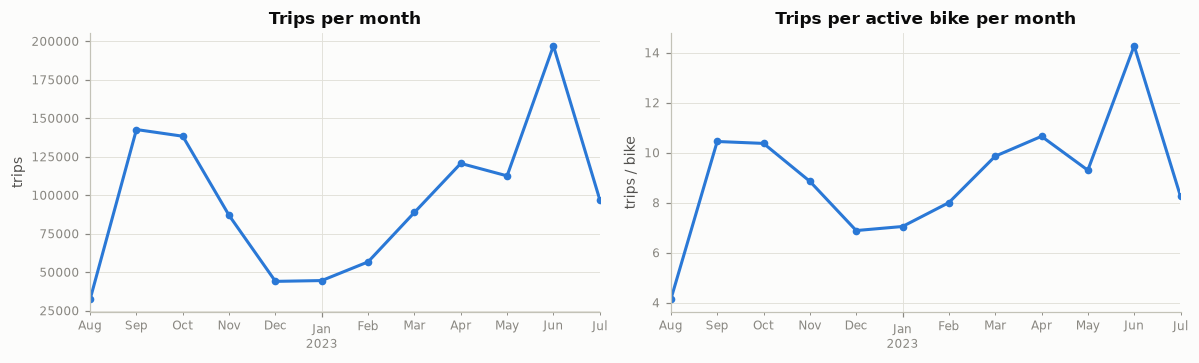

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
monthly.trips.plot(ax=ax[0], marker="o", ms=4)
ax[0].set(title="Trips per month", xlabel="", ylabel="trips")
monthly.trips_per_bike.plot(ax=ax[1], marker="o", ms=4)
ax[1].set(title="Trips per active bike per month", xlabel="", ylabel="trips / bike")
plt.tight_layout()
plt.show()

_Team notes:_

## 5. External data: hourly weather (Open-Meteo archive)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Fetched hourly temperature, precipitation and wind per city from the Open-Meteo archive API (cached to `data/external/weather_hourly.csv`) and joined them to trips by UTC hour.
- City-day demand relative to each city's mean, against daytime temperature and rain (cities with > 2,000 trips; rain chart only on days > 10 °C).
- Spearman correlations on all days and within city-month.

**Not done by Claude**
- No regression controlling for season, weekday and weather together.
- Weather is taken at the city's centre point, not per station.
- No other external data (holidays, events, population, elevation).

In [25]:
need = cities[cities.id.isin(t.city_id) | cities.id.isin(stations.city_id)]
weather = bc.fetch_weather(need)
wl = bc.weather_lookup(weather)
print(weather.shape, weather.city_id.nunique(), "cities")
weather.head()

(1447440, 5) 185 cities


,time_utc,temperature_2m,precipitation,wind_speed_10m,city_id
0,2022-08-25T00:00,19.3,0.0,6.2,220
1,2022-08-25T01:00,19.1,0.1,3.0,220
2,2022-08-25T02:00,19.0,0.1,6.1,220
3,2022-08-25T03:00,17.8,0.0,4.6,220
4,2022-08-25T04:00,17.7,0.0,4.0,220


In [26]:
t["hour_epoch"] = (t.time_start // 3600).astype("int64")
t = t.merge(wl, on=["city_id", "hour_epoch"], how="left")
print("trips with weather:", t.temperature_2m.notna().mean())

trips with weather: 1.0


In [27]:
# city-day demand relative to the city's own median day, vs daily weather
wd = weather.assign(utc=pd.to_datetime(weather.time_utc))
wd["date"] = wd.utc.dt.normalize()
wd = wd[wd.utc.dt.hour.between(6, 21)].groupby(["city_id", "date"]).agg(
    temp=("temperature_2m", "mean"), rain_mm=("precipitation", "sum"), wind=("wind_speed_10m", "mean")).reset_index()
cd = t.groupby(["city_id", t.start_utc.dt.normalize().rename("date")]).size().rename("trips").reset_index()
# include zero-trip days within each city's active window
span = cd.groupby("city_id").date.agg(["min", "max"])
full = pd.concat([pd.DataFrame({"city_id": c, "date": pd.date_range(r["min"], r["max"])}) for c, r in span.iterrows()])
cd = full.merge(cd, how="left").fillna({"trips": 0}).merge(wd, on=["city_id", "date"], how="left")
cd["rel_demand"] = cd.trips / cd.groupby("city_id").trips.transform("mean")
cd["weekend"] = cd.date.dt.dayofweek >= 5
cd = cd[cd.groupby("city_id").trips.transform("sum") > 2000]
print(len(cd), "city-days from", cd.city_id.nunique(), "cities")

32647 city-days from 108 cities


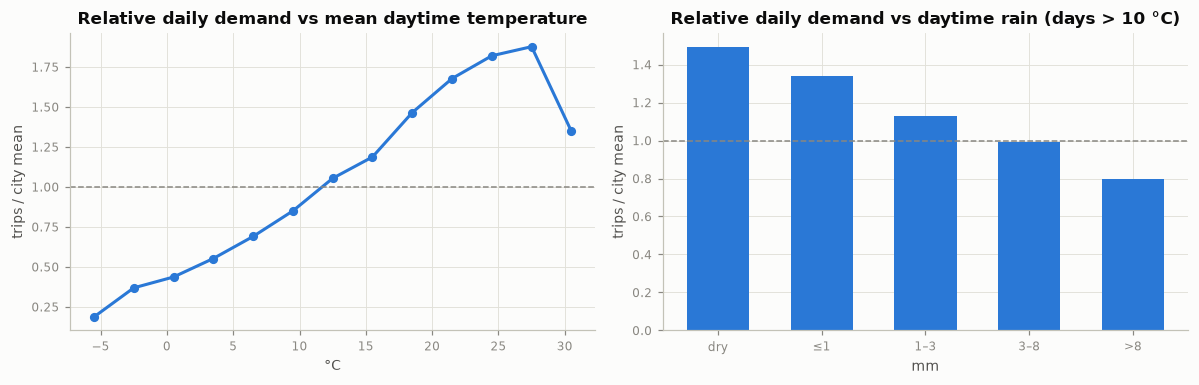

In [28]:
cd["temp_bin"] = pd.cut(cd.temp, bins=range(-10, 36, 3))
cd["rain_bin"] = pd.cut(cd.rain_mm, bins=[-0.1, 0, 1, 3, 8, 100], labels=["dry", "≤1", "1–3", "3–8", ">8"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tb = cd.groupby("temp_bin", observed=True).rel_demand.agg(["mean", "size"])
tb = tb[tb["size"] > 50]
ax[0].plot([i.mid for i in tb.index], tb["mean"], marker="o", ms=5)
ax[0].axhline(1, color=bc.GREY, lw=1, ls="--")
ax[0].set(title="Relative daily demand vs mean daytime temperature", xlabel="°C", ylabel="trips / city mean")
rb = cd[cd.temp > 10].groupby("rain_bin", observed=True).rel_demand.mean()
ax[1].bar(rb.index.astype(str), rb.values, color=bc.SERIES[0], width=0.6)
ax[1].axhline(1, color=bc.GREY, lw=1, ls="--")
ax[1].set(title="Relative daily demand vs daytime rain (days > 10 °C)", xlabel="mm", ylabel="trips / city mean")
plt.tight_layout()
plt.show()

In [29]:
# separate weather from season: within-month correlation of demand and weather
cd["month"] = cd.date.dt.to_period("M")
cd["rel_month"] = cd.trips / cd.groupby(["city_id", "month"]).trips.transform("mean")
pd.DataFrame({
    "corr all days": cd[["rel_demand", "temp", "rain_mm", "wind"]].corr(method="spearman").rel_demand,
    "corr within city-month": cd[["rel_month", "temp", "rain_mm", "wind"]].corr(method="spearman").rel_month,
}).drop(["rel_demand", "rel_month"], errors="ignore").round(3)

,corr all days,corr within city-month
rain_mm,-0.165,-0.224
temp,0.482,0.098
wind,-0.136,-0.062


_Team notes:_

## 6. E-bikes vs human bikes

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Aggregate comparison; within-city ratios for cities with mixed fleets; battery % per km by temperature band.

**Not done by Claude**
- No significance tests.

In [30]:
cmp = t.groupby("ebike").agg(
    trips=("bike_id", "size"), bikes=("bike_id", "nunique"),
    median_min=("duration", lambda x: x.median() / 60), median_km=("distance", lambda x: x.median() / 1000),
    p90_km=("distance", lambda x: x.quantile(.9) / 1000), median_speed=("speed_kmh", "median"),
    round_trip=("round_trip", "mean"), weekend=("weekend", "mean"),
    trips_per_bike=("bike_id", lambda x: len(x) / x.nunique()))
cmp.round(3)

,trips,bikes,median_min,median_km,p90_km,median_speed,round_trip,weekend,trips_per_bike
ebike,,,,,,,,,
0,981285,23212,12.0,1.308,3.264,7.395,0.002,0.233,42.275
1,180091,3212,13.0,1.671,3.957,8.527,0.001,0.213,56.068


In [31]:
# within the same city (removes the city-mix effect)
both = t.groupby("city_id").ebike.agg(["mean", "size"]).query("0.1 < `mean` < 0.9 and size > 2000").index
w = t[t.city_id.isin(both)].groupby(["city_id", "ebike"])[["distance", "speed_kmh", "duration"]].median().unstack()
ratio = pd.DataFrame({c: w[(c, 1)] / w[(c, 0)] for c in ["distance", "speed_kmh", "duration"]})
print(len(both), "cities with mixed fleets")
ratio.describe().round(3)

12 cities with mixed fleets


,distance,speed_kmh,duration
count,12.000,12.000,12.000
mean,1.100,1.071,1.138
std,0.343,0.260,0.315
min,0.612,0.528,0.867
25%,0.973,0.900,0.934
50%,1.064,1.172,1.000
75%,1.231,1.217,1.280
max,1.961,1.440,2.000


In [32]:
# battery drain per km for e-bikes
eb = t[(t.ebike == 1) & t.battery_used.between(0, 100) & (t.distance > 500)].copy()
eb["pct_per_km"] = eb.battery_used / (eb.distance / 1000)
print(eb.pct_per_km.describe(percentiles=[.25, .5, .75]).round(3))
eb.groupby(pd.cut(eb.temperature_2m, [-15, 0, 5, 10, 15, 20, 25, 40]), observed=True).pct_per_km.agg(["median", "size"]).round(3)

count    157637.000
mean          2.643
std           3.579
min           0.000
25%           0.000
50%           1.928
75%           3.541
max         107.513
Name: pct_per_km, dtype: float64


,median,size
temperature_2m,,
"(-15, 0]",1.962,1919
"(0, 5]",1.981,7334
"(5, 10]",1.937,17858
"(10, 15]",1.922,29869
"(15, 20]",1.975,40816
"(20, 25]",1.896,37321
"(25, 40]",1.913,22519


_Team notes:_

## 7. Station status: structure of the log

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Share of identical consecutive records, gaps between records, size of changes, the check bikes = available + booked, negative `booked_bikes`, maintenance share.
- Observed capacity = 99th percentile of bikes + free racks + free special racks; declared vs observed capacity; virtual station = 0 declared racks.

**Not done by Claude**
- Records failing bikes = available + booked are kept, not fixed.
- Declared rack counts in `stations.csv` are not corrected.

In [33]:
s = bc.clean_status(status)
cols = bc.STATE_COLS
same = (s[cols] == s.groupby("station_id")[cols].shift()).all(axis=1)
gap = s.groupby("station_id").time.diff()
print("consecutive identical records:", round(same.mean(), 5))
print("record gap (min) quantiles:")
(gap / 60).describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1)

consecutive identical records: 0.00013
record gap (min) quantiles:


count    2923068.0
mean         366.6
std         3416.9
min            0.8
5%             1.0
25%            4.0
50%           28.0
75%          158.0
95%         1295.0
99%         4704.0
max       414736.0
Name: time, dtype: float64

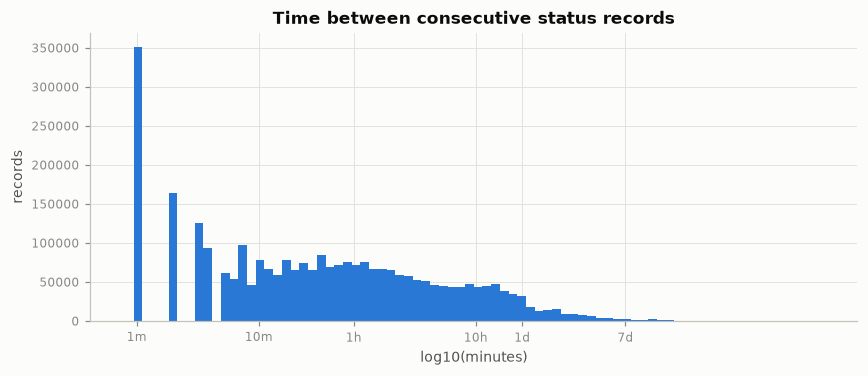

In [34]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(np.log10(gap.dropna() / 60), bins=80, color=bc.SERIES[0])
ax.set(title="Time between consecutive status records", xlabel="log10(minutes)", ylabel="records",
       xticks=np.log10([1, 10, 60, 600, 1440, 10080]), xticklabels=["1m", "10m", "1h", "10h", "1d", "7d"])
plt.show()

In [35]:
d_av = s.groupby("station_id").bikes_available_to_rent.diff()
print("size of change in available bikes between records:")
d_av.abs().value_counts(normalize=True).head(6).round(4)

size of change in available bikes between records:


bikes_available_to_rent
1.0    0.8236
2.0    0.0786
0.0    0.0747
3.0    0.0130
4.0    0.0051
5.0    0.0021
Name: proportion, dtype: float64

In [36]:
# internal consistency
print("bikes == available + booked:", (status.bikes == status.bikes_available_to_rent + status.booked_bikes).mean().round(5))
print("records with negative booked_bikes:", (status.booked_bikes < 0).sum())
print("records in maintenance:", status.maintenance.mean().round(4))

bikes == available + booked: 0.9992
records with negative booked_bikes: 160
records in maintenance: 0.0446


stations with 0 declared racks: 0.416
negative special_racks: 32
rack stations where observed capacity > declared: 0.678


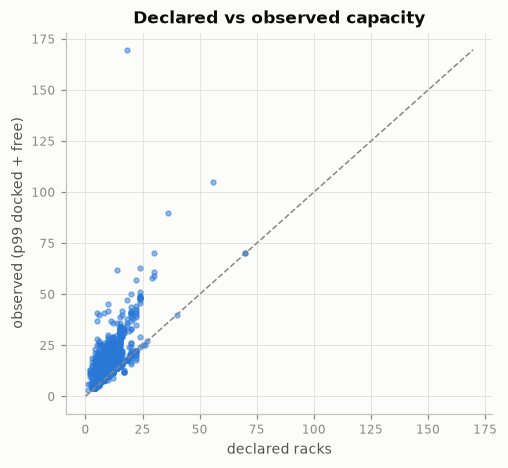

In [37]:
st = stations.set_index("id")
st["declared_cap"] = st.bike_racks + st.special_racks.clip(lower=0)
cap = bc.station_capacity(s)
st = st.join(cap)
st["virtual"] = (st.declared_cap == 0).astype(int)
print("stations with 0 declared racks:", st.virtual.mean().round(3))
print("negative special_racks:", (stations.special_racks < 0).sum())
rack = st[(st.virtual == 0) & st.capacity.notna()]
print("rack stations where observed capacity > declared:", (rack.capacity > rack.declared_cap).mean().round(3))
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(rack.declared_cap, rack.capacity, s=10, alpha=.5, color=bc.SERIES[0])
lim = max(rack.declared_cap.max(), rack.capacity.max())
ax.plot([0, lim], [0, lim], color=bc.GREY, lw=1, ls="--")
ax.set(title="Declared vs observed capacity", xlabel="declared racks", ylabel="observed (p99 docked + free)")
plt.show()

In [38]:
mshare = s.groupby("station_id").maintenance.mean()
print("stations never in maintenance:", (mshare == 0).mean().round(3), "| always:", (mshare == 1).mean().round(3))
mshare[mshare > 0].describe().round(3)

stations never in maintenance: 0.97 | always: 0.027


count    86.000
mean      0.955
std       0.174
min       0.002
25%       1.000
50%       1.000
75%       1.000
max       1.000
Name: maintenance, dtype: float64

_Team notes:_

## 8. Station status on an hourly grid

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Hourly as-of grid: each hour takes the last record at or before it. Hours inside gaps > 7 days are marked invalid.
- Coverage by month, empty/full shares, fill by hour, per-station share of empty hours, distribution of the 1-hour change.

**Not done by Claude**
- Gaps of up to 7 days are carried forward, not treated as missing. The 7-day threshold was not tuned.

In [39]:
g = bc.hourly_grid(s)
g = g.merge(st[["city_id", "capacity", "virtual"]], left_on="station_id", right_index=True, how="left")
g["utc"] = pd.to_datetime(g.hour_epoch * 3600, unit="s")
print(f"{len(g):,} station-hours, valid share {g.valid.mean():.3f}")
cov = g.groupby(g.utc.dt.to_period("M")).agg(valid=("valid", "mean"), stations=("station_id", "nunique"))
cov.round(3)

17,859,323 station-hours, valid share 0.705


,valid,stations
utc,,
2022-08,0.972,2232
2022-09,0.862,2518
2022-10,0.828,2570
2022-11,0.719,2504
2022-12,0.543,2286
2023-01,0.543,2311
2023-02,0.571,2231
2023-03,0.660,2298
2023-04,0.771,2324


In [40]:
gv = g[g.valid & (g.maintenance == 0)].copy()
gv["local"] = bc.local_time(gv.hour_epoch * 3600, gv.city_id.map(cities.set_index("id").timezone))
gv = bc.add_calendar(gv, "local")
gv["is_empty"] = gv.bikes_available_to_rent == 0
gv["full"] = (gv.free_racks + gv.free_special_racks == 0) & (gv.virtual == 0)
gv["fill"] = gv.bikes / gv.capacity
pd.Series({"empty share": gv.is_empty.mean(), "full share (rack stations)": gv.loc[gv.virtual == 0, "full"].mean(),
           "median fill": gv["fill"].median()}).round(3)

empty share                   0.103
full share (rack stations)    0.126
median fill                   0.333
dtype: float64

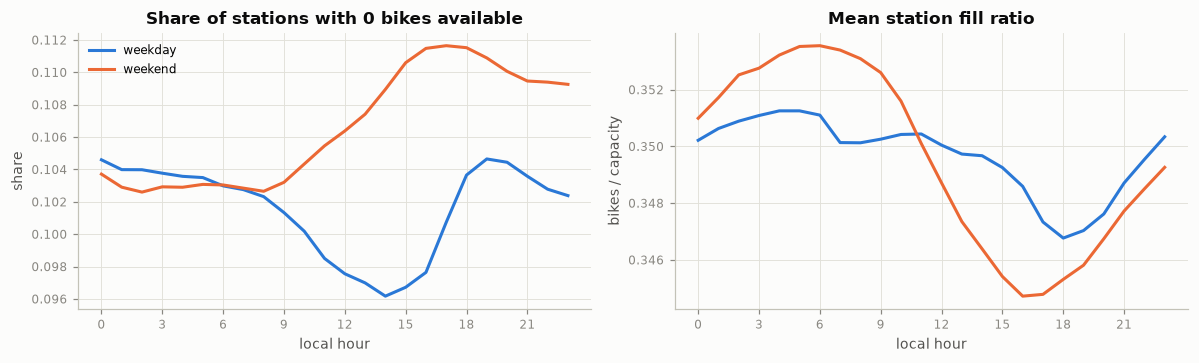

In [41]:
eh = gv.groupby(["weekend", "hour"])[["is_empty", "fill"]].mean().unstack(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for k, lab in [(0, "weekday"), (1, "weekend")]:
    ax[0].plot(eh.index, eh[("is_empty", k)], label=lab)
    ax[1].plot(eh.index, eh[("fill", k)], label=lab)
ax[0].set(title="Share of stations with 0 bikes available", xlabel="local hour", ylabel="share", xticks=range(0, 24, 3))
ax[1].set(title="Mean station fill ratio", xlabel="local hour", ylabel="bikes / capacity", xticks=range(0, 24, 3))
ax[0].legend()
plt.tight_layout()
plt.show()

stations empty > 50% of valid hours: 0.021
stations never empty: 0.133


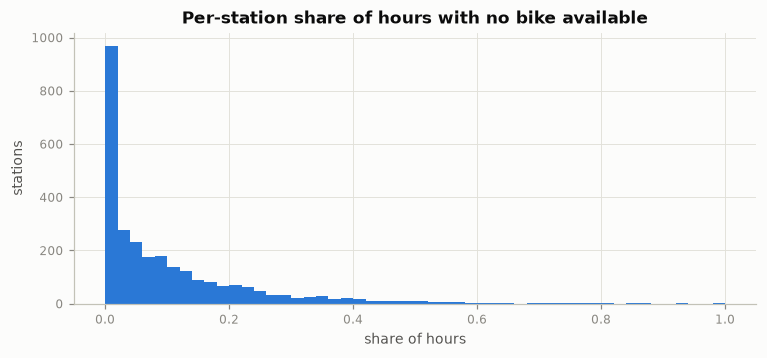

In [42]:
# how concentrated is emptiness? share of station-hours empty per station
emp = gv.groupby("station_id").is_empty.mean()
print("stations empty > 50% of valid hours:", (emp > .5).mean().round(3))
print("stations never empty:", (emp == 0).mean().round(3))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(emp, bins=50, color=bc.SERIES[0])
ax.set(title="Per-station share of hours with no bike available", xlabel="share of hours", ylabel="stations")
plt.show()

In [43]:
# hourly change in available bikes: how often does anything happen within one hour?
gs = g.sort_values(["station_id", "hour_epoch"])
nxt = gs.groupby("station_id").bikes_available_to_rent.shift(-1)
ok = gs.valid & (gs.maintenance == 0)
dh1 = (nxt - gs.bikes_available_to_rent)[ok].dropna()
print("1h-ahead change == 0:", (dh1 == 0).mean().round(3))
dh1.clip(-6, 6).value_counts(normalize=True).sort_index().round(4)

1h-ahead change == 0: 0.896


bikes_available_to_rent
-6.0    0.0007
-5.0    0.0005
-4.0    0.0011
-3.0    0.0026
-2.0    0.0092
-1.0    0.0384
 0.0    0.8955
 1.0    0.0379
 2.0    0.0089
 3.0    0.0027
 4.0    0.0012
 5.0    0.0006
 6.0    0.0007
Name: proportion, dtype: float64

_Team notes:_

## 9. Trips vs status: how big is the trip sample, and station imbalance

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Per station: decreases in docked bikes in the status log vs departures in the trip file.
- Weekday AM (06–10 h) and PM (16–20 h) net inflow for stations with > 400 trips.

**Not done by Claude**
- Rebalancing (truck) moves are not separated from rides.

In [44]:
# docked-bike decrements in the status log vs departures recorded in trips, per station
dec = (-s.groupby("station_id").bikes.diff()).clip(lower=0).groupby(s.station_id).sum()
inc = s.groupby("station_id").bikes.diff().clip(lower=0).groupby(s.station_id).sum()
dep = t.station_id_start.value_counts()
arr = t.station_id_end.value_counts()
flow = pd.DataFrame({"status_decrements": dec, "status_increments": inc, "trip_departures": dep, "trip_arrivals": arr}).dropna()
flow = flow[flow.status_decrements > 50]
print("median departures/decrements ratio:", (flow.trip_departures / flow.status_decrements).median().round(3))
print("spearman(departures, decrements):", flow[["trip_departures", "status_decrements"]].corr("spearman").iloc[0, 1].round(3))

median departures/decrements ratio: 0.7
spearman(departures, decrements): 0.94


1058 busy stations
corr(AM net inflow, PM net inflow): -0.417


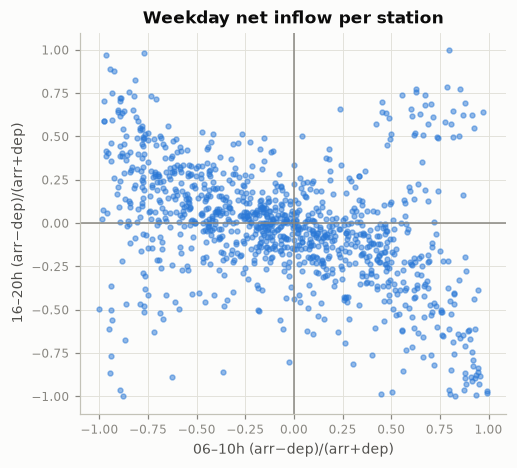

In [45]:
# per station net flow (arrivals - departures) by local hour, weekdays
ts = t[(t.weekend == 0)]
dep_h = ts.dropna(subset=["station_id_start"]).groupby(["station_id_start", "hour"]).size()
arr_h = ts.dropna(subset=["station_id_end"]).assign(end_hour=lambda d: (d.start_local + pd.to_timedelta(d.duration, "s")).dt.hour) \
    .groupby(["station_id_end", "end_hour"]).size()
dep_h.index.names = arr_h.index.names = ["station_id", "hour"]
nf = pd.concat({"dep": dep_h, "arr": arr_h}, axis=1).fillna(0)
tot = nf.groupby("station_id").sum()
busy = tot[(tot.dep + tot.arr) > 400].index
nf = nf.loc[busy]
am = nf[nf.index.get_level_values("hour").isin(range(6, 10))].groupby("station_id").sum()
pm = nf[nf.index.get_level_values("hour").isin(range(16, 20))].groupby("station_id").sum()
imb = pd.DataFrame({"am_net": (am.arr - am.dep) / (am.arr + am.dep).clip(lower=1),
                    "pm_net": (pm.arr - pm.dep) / (pm.arr + pm.dep).clip(lower=1),
                    "overall_net": (tot.arr - tot.dep) / (tot.arr + tot.dep)}).loc[busy].dropna()
print(len(imb), "busy stations")
print("corr(AM net inflow, PM net inflow):", imb[["am_net", "pm_net"]].corr().iloc[0, 1].round(3))
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(imb.am_net, imb.pm_net, s=10, alpha=.5, color=bc.SERIES[0])
ax.axhline(0, color=bc.GREY, lw=1)
ax.axvline(0, color=bc.GREY, lw=1)
ax.set(title="Weekday net inflow per station", xlabel="06–10h (arr−dep)/(arr+dep)", ylabel="16–20h (arr−dep)/(arr+dep)")
plt.show()

In [46]:
print("stations with |overall net| > 0.2 (structural sources/sinks):", (imb.overall_net.abs() > .2).mean().round(3))
imb.describe().round(3)

stations with |overall net| > 0.2 (structural sources/sinks): 0.097


,am_net,pm_net,overall_net
count,1058.000,1058.000,1058.000
mean,-0.068,-0.022,-0.018
std,0.505,0.342,0.182
min,-1.000,-1.000,-0.933
25%,-0.463,-0.200,-0.049
50%,-0.091,-0.009,-0.015
75%,0.331,0.171,0.009
max,0.992,1.000,0.916


_Team notes:_

## 10. Correlation of trip-level variables

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Spearman correlation heatmap of trip-level variables.

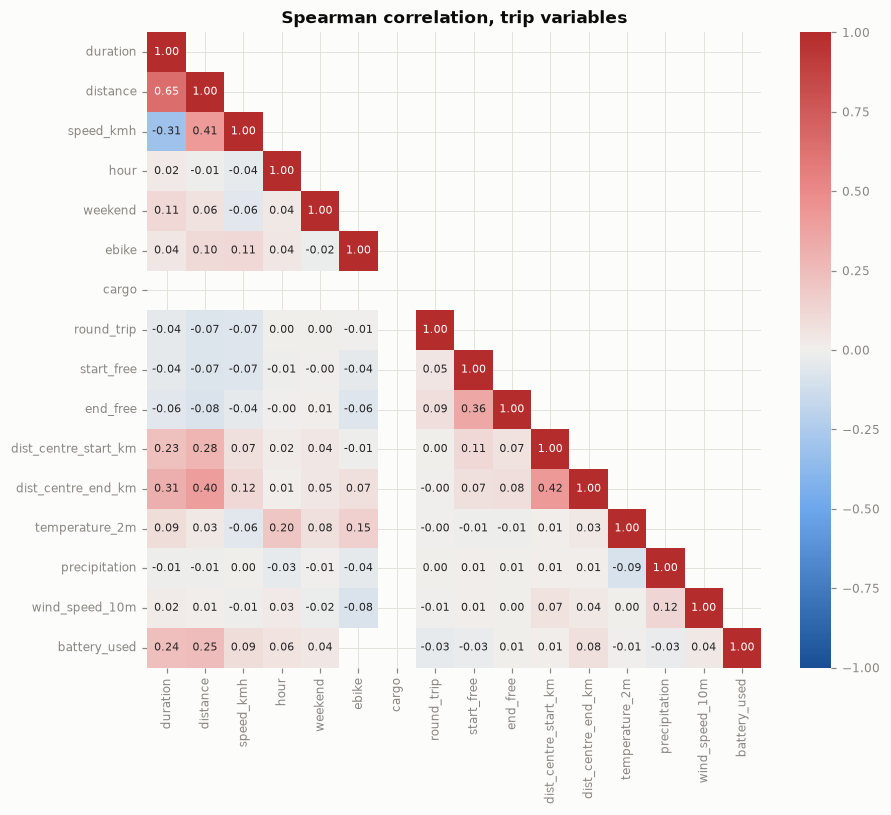

In [47]:
num = ["duration", "distance", "speed_kmh", "hour", "weekend", "ebike", "cargo", "round_trip", "start_free", "end_free",
       "dist_centre_start_km", "dist_centre_end_km", "temperature_2m", "precipitation", "wind_speed_10m", "battery_used"]
corr = t[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap=bc.DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax,
            mask=np.triu(np.ones_like(corr, bool), k=1))
ax.set_title("Spearman correlation, trip variables")
plt.show()

_Team notes:_

## 11. Save cleaned tables

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Saved `trips_clean.pkl`, `status_clean.pkl` and `stations_meta.pkl` to `data/cleaned/` for notebooks 02–05.

**Not done by Claude**
- No CSV export (pickles only, because pyarrow is not installed).

In [48]:
keep = ["bike_id", "city_id", "city_name", "country", "time_start", "start_utc", "start_local", "date",
        "hour", "dow", "weekend", "month", "hour_sin", "hour_cos", "doy_sin", "doy_cos",
        "lon_start", "lat_start", "lon_end", "lat_end", "station_id_start", "station_id_end",
        "battery_start", "battery_end", "battery_used", "duration", "distance", "speed_kmh",
        "bike_type_id", "ebike", "cargo", "start_free", "end_free", "same_station", "round_trip",
        "dist_centre_start_km", "dist_centre_end_km", "return_to_official_only",
        "hour_epoch", "temperature_2m", "precipitation", "wind_speed_10m"]
trips_clean = t[keep].reset_index(drop=True)
bc.save_clean(trips_clean, "trips_clean")
bc.save_clean(s, "status_clean")
station_meta = st.reset_index().rename(columns={"index": "id"})[
    ["id", "city_id", "name", "terminal_type", "place_type", "bike_racks", "special_racks", "declared_cap", "capacity", "virtual", "lat", "lon"]]
bc.save_clean(station_meta, "stations_meta")
print(trips_clean.shape, s.shape, station_meta.shape)

(1161376, 42) (2925967, 9) (2932, 12)
